In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import sys
import time
sys.path.append('./FUNCIONES')
sys.path.append("imagenEntrada")

# PRÁCTICA 5 Simulación y Filtrado de Ruidos en Imágenes

Objetivo: simulación y filtrado de ruidos en imágenes; evaluación de distintos tipos y
opciones de filtrado. 

La práctica se ha dividido en tres partes:

1. **Primera parte**: simulación de ruidos tipo gaussiano y sal y pimienta.

2. **Segunda parte**: implementación de filtros gaussiano, mediana y adaptativo.

3. **Tercera parte**: evaluación de eficiencia de filtros gaussiano, mediana y adaptativo.


## PRIMERA PARTE: Simulación de ruidos.

1. 1. Lee la imagen en escala de gris “img.png”.

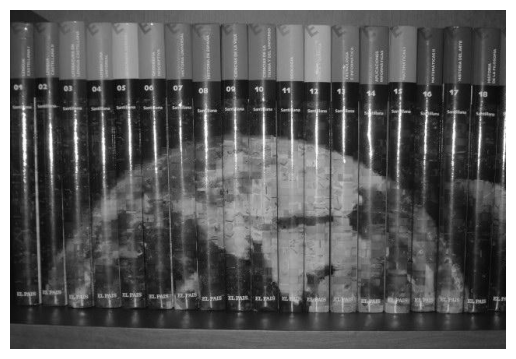

(436, 637)

In [2]:
I = cv2.imread("imagenEntrada/img.png")

I = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

plt.imshow(I, cmap="gray")
plt.axis("off")
plt.show()



I.shape

2. Corrompe la imagen anterior con ruido de tipo de sal y pimienta y de tipo gaussiano para
generar imágenes ruidosas, tal y como se describe a continuación:

a. Sal y pimienta, con p = 0.9 y q = 0.95 (ver ecuación). La imagen corrompida con este
ruido (imagen A) se calculará de la siguiente manera:

```md
            [I(i,j)     x < p] siendo I la imagen original sin corromper, x una variable aleatoria uniforme de rango (0,1)
A(i, j) =   [0     p <= x < q] q-p el porcentaje de pixeles con ruido tipo pimienta
            [255   q <= x < 1] y 1-q el porcentaje de ruido de tipo sal
```

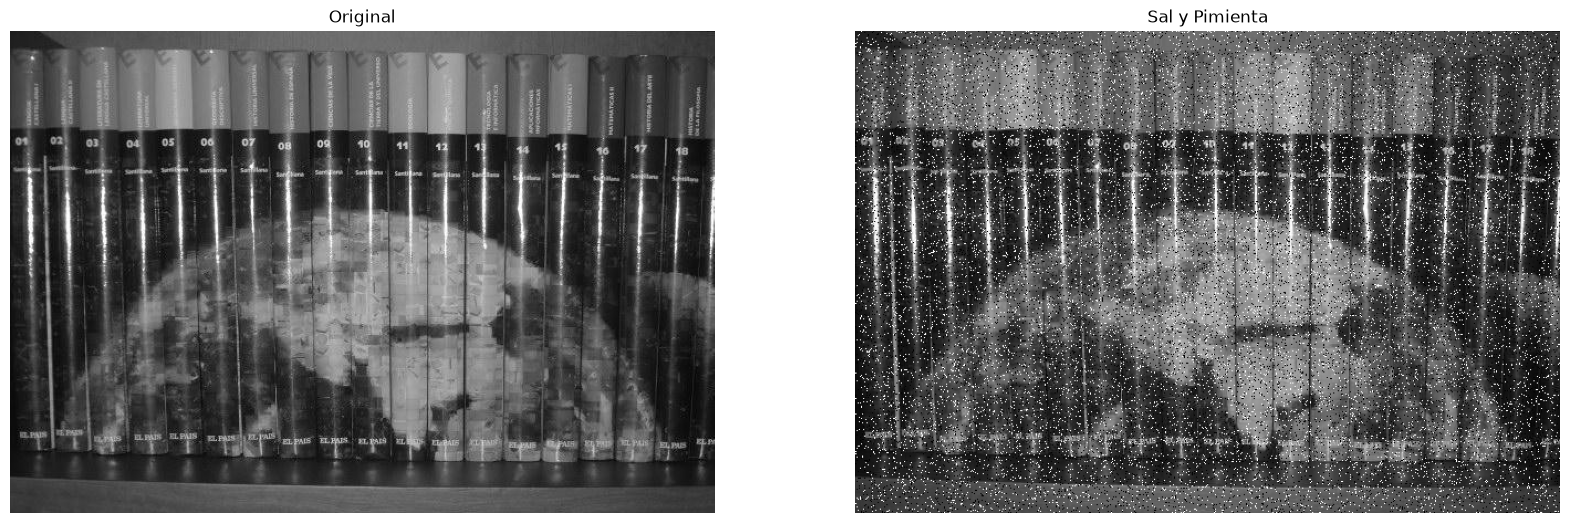

In [4]:
alto, ancho = I.shape

np.random.seed(14)

matriz_rnd = np.random.random((alto, ancho))
p = 0.9
q = 0.95

SyP = I.copy()

SyP[(matriz_rnd >= p) & (matriz_rnd < q)] = 0
SyP[matriz_rnd >= q]  = 255

plt.figure(figsize=(20,10))
plt.subplot(1,2,1)
plt.imshow(I, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(SyP, cmap="gray")
plt.title("Sal y Pimienta")
plt.axis("off")

plt.show()

b. Gaussiano de media nula y desviación típica 5, 10, 35 y 50. 

**Apunte teórico**

Sea N(0,1) una función distribución de probabilidad normal o gaussiana de media cero y varianza 1
(N(0,1)). Utilizando esta distribución, se puede obtener otra distribución gaussiana de media u y varianza σ^2(N(u, σ^2)):

```md
            N (u,σ^2) - u
N(0,1) = ___________________
                σ
```


In [5]:
alto, ancho = I.shape
media = 0
desviaciones = np.array([5, 10, 35, 50])

Gaussianos = np.zeros((alto, ancho, len(desviaciones)), dtype=np.uint8)
np.random.seed(14)

for i in range(len(desviaciones)):
    ruido =  np.random.normal(media, desviaciones[i], I.shape)
    G = np.clip(np.round(I.astype(np.float32) + ruido), 0, 255).astype(np.uint8)
    Gaussianos[:,:,i] = G


3. Visualiza la imagen original y las 5 imágenes ruidosas generadas (en una misma ventana
gráfica).


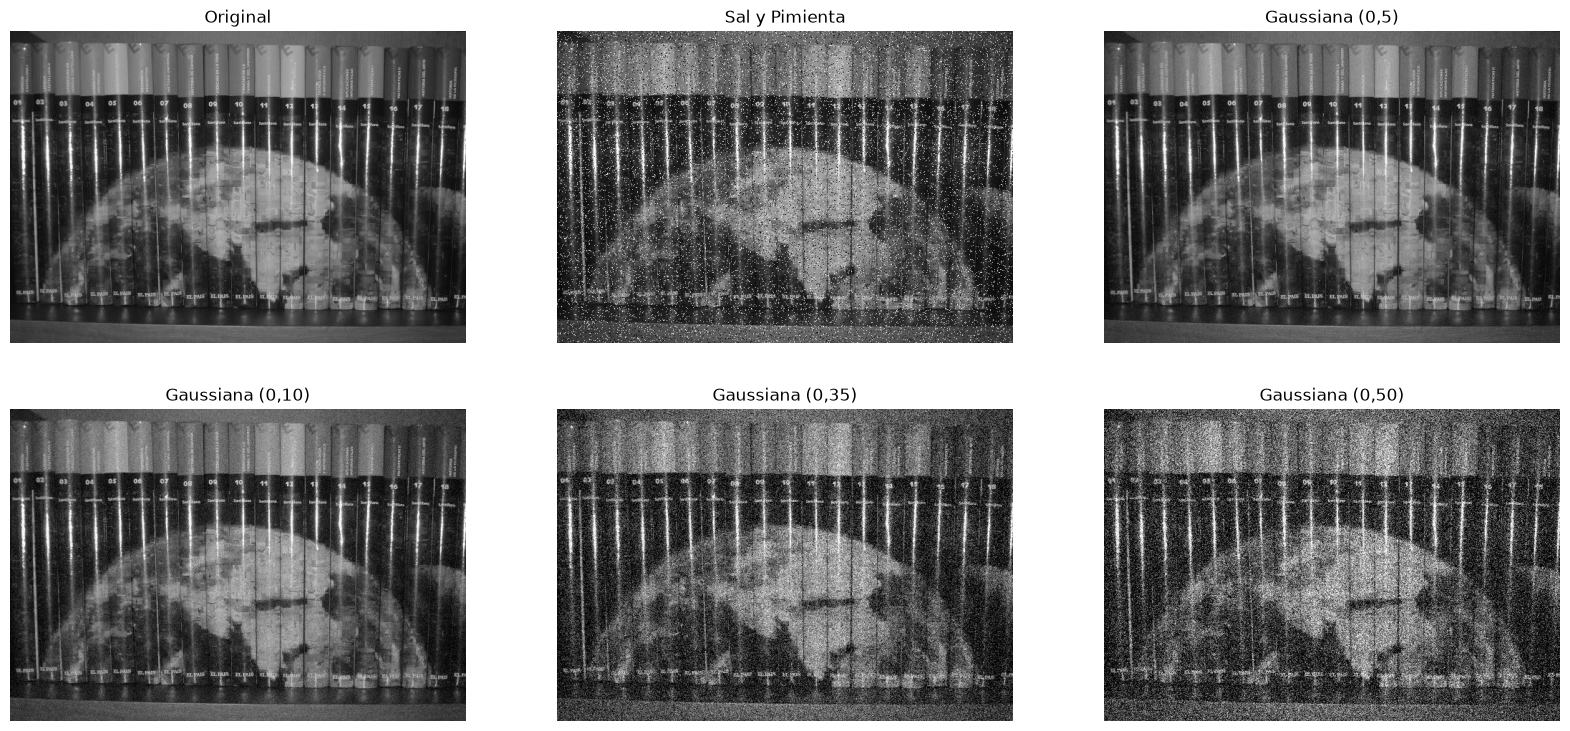

In [6]:
titulos = ["Original", "Sal y Pimienta", "Gaussiana (0,5)", "Gaussiana (0,10)", "Gaussiana (0,35)", "Gaussiana (0,50)"]
imagenes = [I, SyP, Gaussianos[:,:,0], Gaussianos[:,:,1], Gaussianos[:,:,2], Gaussianos[:,:,3]]
plt.figure(figsize=(20,9))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes[i], cmap="gray")
    plt.title(titulos[i])
    plt.axis("off")

plt.show()

4. Representa en un mismo gráfico la variación de los niveles de gris a lo largo de la línea
horizontal central para la imagen original, para la imagen contaminada con ruido de tipo
sal y pimienta, y para la imagen corrompida con ruido gaussiano de desviación típica 10.
Observa las distintas distribuciones del ruido.

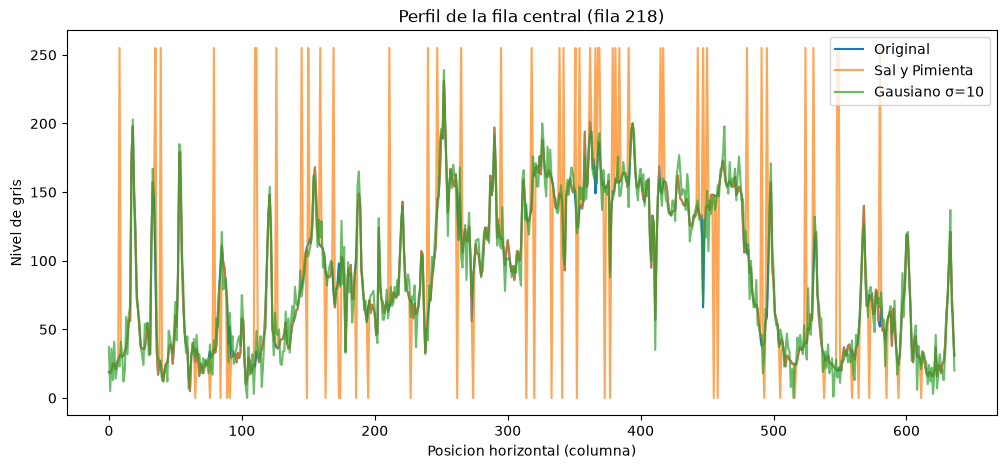

In [38]:
alto, ancho = I.shape

fila = alto // 2

plt.figure(figsize=(12,5))
plt.plot(I[fila,:], label="Original")
plt.plot(SyP[fila, :], label="Sal y Pimienta", alpha=0.7)
plt.plot(Gaussianos[fila, :, 1], label="Gausiano σ=10", alpha=0.7)

plt.xlabel("Posicion horizontal (columna)")
plt.ylabel("Nivel de gris")
plt.title(f'Perfil de la fila central (fila {fila})')
plt.legend()
plt.show()

5. En un directorio de Imágenes Generadas, almacena la imagen corrompida con ruido sal y
pimienta y las cuatro imágenes corrompidas con ruidos gaussiano (media nula y
desviaciones típicas 5, 10, 35 y 50).

In [39]:

cv2.imwrite("ImagenesGeneradas/syp.png", SyP)
cv2.imwrite("ImagenesGeneradas/g5.png", Gaussianos[:,:,0])
cv2.imwrite("ImagenesGeneradas/g10.png", Gaussianos[:,:,1])
cv2.imwrite("ImagenesGeneradas/g35.png", Gaussianos[:,:,2])
cv2.imwrite("ImagenesGeneradas/g50.png", Gaussianos[:,:,3])

True

**Objetivo teórico**: conocer los dos tipos de ruido, su forma de manifestarse en imágenes
digitales y saber cómo se pueden simular e implementar

## SEGUNDA PARTE: Implementación de filtros gaussiano, mediana y adaptativo.

### 2.1.-Filtro Gaussiano

a. Implementación de kernel de convolución de un filtro gaussiano (este apartado debe
realizarse en un cuaderno Jupyter independiente)

-  Crea la máscara del filtro gaussiano 5x5, considerando la relación W = 5 σ (siendo σ la
desviación típica del filtro y W sus dimensiones), utilizando el siguiente código
(programación vectorizada sin bucles):

```md
W = 5; sigma = W/5
mitad = int(W//2)
X = np.arange(-mitad, mitad + 1)
Y = np.arange(-mitad, mitad + 1)
X2, Y2 = np.meshgrid(X, Y)
hg = np.exp(-0.5 * (X2**2 + Y2**2) / (sigma**2))
hg = hg / np.sum(hg)
```

- Crea la misma máscara, pero implementando un doble bucle for para generar cada uno
de sus valores. 

- Utiliza la función de OpenCV getGaussianKernel para generar los valores de la
máscara y comprueba que se obtienen los mismos resultados en los tres casos (pueden
asumirse diferencias máximas del orden de 10^(-8) ).


**Observacion:**

getGaussianKernel devuelve un vector columna; se debe multiplicar este vector por su
traspuesto para obtener la máscara 2D:

gk = cv2.getGaussianKernel(W, sigma); hg = gk @ gk.T

- Visualiza la máscara en una representación de superficie 3D utilizando el siguiente
código:

```md
W = hg.shape[0]
mitad = W//2
X = np.arange(-mitad, mitad + 1); Y = np.arange(-mitad, mitad + 1)
X2, Y2 = np.meshgrid(X, Y)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X2, Y2, hg, cmap='viridis')
ax.set_title('Máscara Gaussiana 3D')
plt.show()
```


vec vs bucle: 0.0
vec vs cv   : 1.734723475976807e-18
bucle vs cv : 1.734723475976807e-18
¿iguales?   : True
Suma de la máscara: 1.0


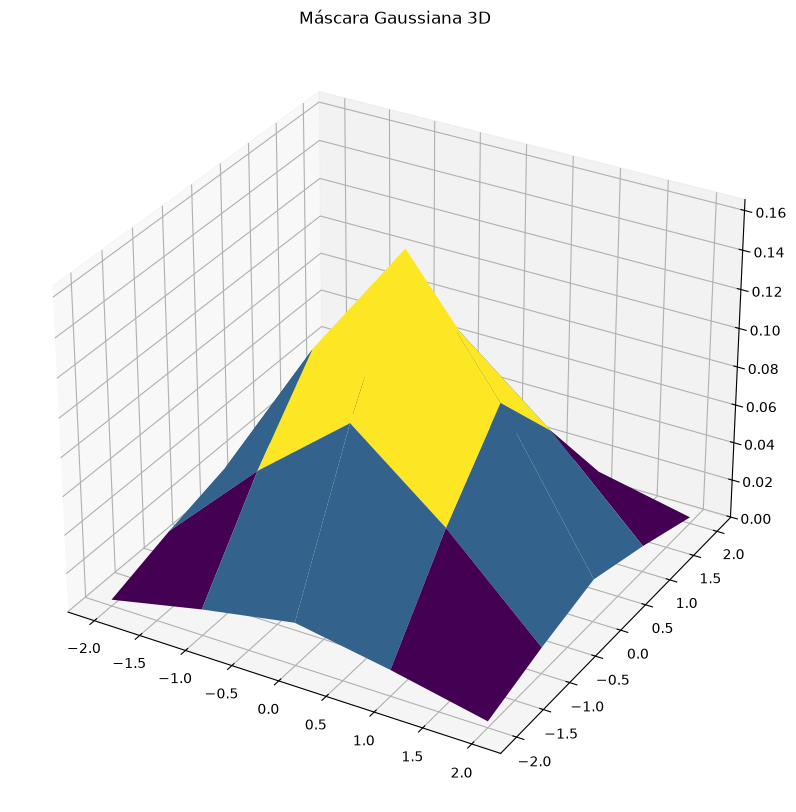

In [3]:
W = 5; sigma = W/5
mitad = int(W//2)

# 1) Vectorizada
X = np.arange(-mitad, mitad + 1)
Y = np.arange(-mitad, mitad + 1)
X2, Y2 = np.meshgrid(X,Y)
hg_vec =np.exp(-0.5 * (X2**2 + Y2**2) / (sigma**2))
hg_vec = hg_vec / np.sum(hg_vec)

# 2) Doble bucle
hg_bucle = np.zeros((W,W))
for i in range(W):
    for j in range(W):
        x = j - mitad          # columna -> x
        y = i - mitad          # fila    -> y
        hg_bucle[i, j] = np.exp(-0.5 * (x**2 + y**2) / (sigma**2))
hg_bucle = hg_bucle / np.sum(hg_bucle)

# 3) OpenCV
gk = cv2.getGaussianKernel(W, sigma)
hg_cv = gk @ gk.T

# Comprobación
print("vec vs bucle:", np.max(np.abs(hg_vec - hg_bucle)))
print("vec vs cv   :", np.max(np.abs(hg_vec - hg_cv)))
print("bucle vs cv :", np.max(np.abs(hg_bucle - hg_cv)))
print("¿iguales?   :", np.allclose(hg_vec, hg_bucle, atol=1e-8) and
                       np.allclose(hg_vec, hg_cv, atol=1e-8))
print("Suma de la máscara:", hg_vec.sum())

#3D
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X2, Y2, hg_vec, cmap='viridis')
ax.set_title('Máscara Gaussiana 3D')
plt.show()

b. Utilizando padding de ceros, aplica un filtro de media simple 9x9 y un filtro gaussiano de la misma vecindad (se debe utilizar la función getGaussianKernel para la obtención del kernel de convolución) sobre la imagen corrompida con ruido sal y pimienta. Visualiza los resultados (imagen de entrada y dos imágenes filtradas) en una misma ventana gráfica. Analiza las imágenes.

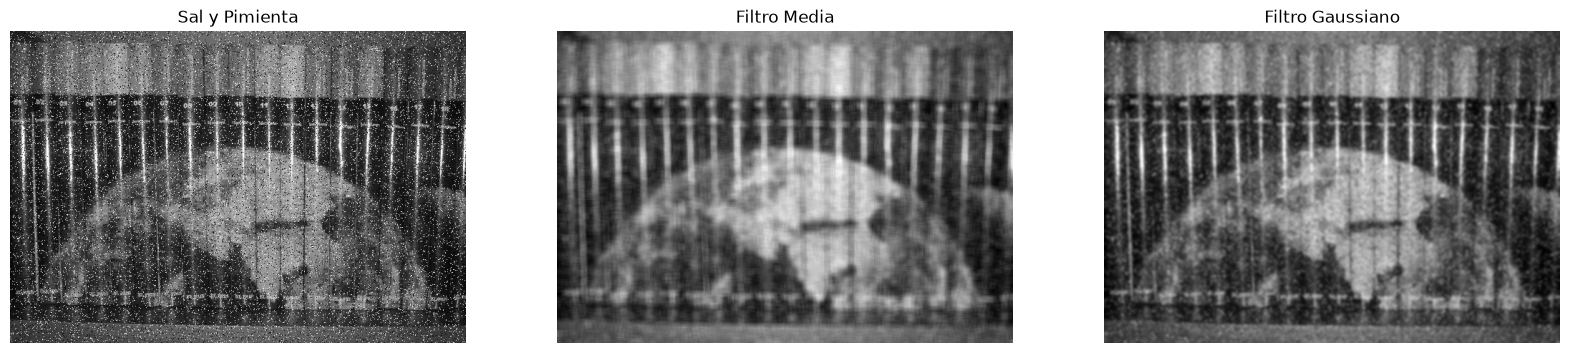

In [3]:
W = 9

h_medias = np.ones((W,W), dtype=np.float32) / (W*W)
hg = cv2.getGaussianKernel(W, W/5) @ cv2.getGaussianKernel(W, W/5).T

SyP = cv2.imread("ImagenesGeneradas/syp.png", cv2.IMREAD_GRAYSCALE)

filtro_media = cv2.filter2D(SyP, -1, h_medias)
filtro_gaussiano = cv2.filter2D(SyP, -1, hg)

plt.figure(figsize=(20,10))
plt.subplot(1,3,1)
plt.imshow(SyP, cmap="gray")
plt.title("Sal y Pimienta")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(filtro_media, cmap="gray")
plt.title("Filtro Media")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(filtro_gaussiano, cmap="gray")
plt.title("Filtro Gaussiano")
plt.axis("off")
plt.show()


El filtro de medias elimina el ruido de sal y pimienta a costa de perder nitidez en la imagen, dejandonos una imagen muy borrosa en la que ta no se pueden distinguir ni los textos de los libros

En cambio el Filtro Gaussiano no fue capaz de eliminar el ruido sal y pimienta al completo pero conserva algo mas de nitidez que el filtro de medias.

Ninguna de las dos estrategias resuelve bien el problema.

c. Aplica el filtro gaussiano del apartado anterior con la función de OpenCV GaussianBlurr y compara el tiempo computacional y resultados de ambos procedimientos. La comparación se debe hacer con las variables de salida tipo float32 (se asumen diferencias del orden de 10^(-5) ).

In [46]:
W = 9
sigma = W/5

gk = cv2.getGaussianKernel(W, sigma)
h_gauss = (gk @ gk.T).astype(np.float32)

SyP32 = SyP.astype(np.float32)

start = time.perf_counter()
f2d = cv2.filter2D(SyP32, cv2.CV_32F, h_gauss, borderType=cv2.BORDER_CONSTANT)
time1 = time.perf_counter() - start

start = time.perf_counter()
gb  = cv2.GaussianBlur(SyP32, (W, W), sigma, borderType=cv2.BORDER_CONSTANT)
time2 = time.perf_counter() - start


print("Tipos:", f2d.dtype, gb.dtype)
print("Diferencia máxima:", np.max(np.abs(f2d - gb)))
print("Diferencia media :", np.mean(np.abs(f2d - gb)))
print("Tiempo filtro 2D:", time1)
print("Tiempo GaussianBlur:", time2)


Tipos: float32 float32
Diferencia máxima: 0.00010681152
Diferencia media : 1.0058834e-05
Tiempo filtro 2D: 0.0008449000001746754
Tiempo GaussianBlur: 0.0003723999998328509


### 2.2. Filtro de la mediana

a. Implementación de la función filtro_mediana: tomando como base la programación de las funciones filtro_máximos y filtro_mínimos, implementa la función filtro_mediana e incorpórala en el fichero Python de funciones de filtro de orden, funciones_filtro_orden.py.

In [48]:
from funciones_filtro_orden import filtro_mediana, OpcionRelleno

def filtro_mediana(I, V, OpcionRelleno=OpcionRelleno.ZEROS):
    if I.dtype != np.uint8 and I.dtype != np.float32:
         raise ValueError("La imagen debe ser uint8 o float32")
    if I.ndim != 2:
        raise ValueError("Dimension incorrecta la Imagen debe ser en escala de grises")
    if I.dtype == np.uint8:
        Ic = np.float32(I)

    V = np.asarray(V)
    Ic = I.astype(np.float32)

    borderHeight = V.shape[0] // 2
    borderWidth = V.shape[1] // 2

    rellenos = [cv2.BORDER_REPLICATE, cv2.BORDER_REFLECT, cv2.BORDER_CONSTANT]

    pad = cv2.copyMakeBorder(Ic, borderHeight, borderHeight, borderWidth, borderWidth, borderType=rellenos[OpcionRelleno.value])

    alto, ancho = Ic.shape
    mascara = (V == 1)
    Io = np.zeros((alto, ancho), np.float32)

    for i in range(alto):
        for j in range(ancho):
            ventana = pad[i:i + V.shape[0], j:j + V.shape[1]]
            Io[i, j] = np.median(ventana[mascara]).astype(np.uint8)

    return Io

b.
Utilizando padding ‘replicate’ y una vecindad completa 3x3, aplica un filtro de la mediana a la imagen corrompida con ruido sal y pimienta. Debe aplicarse la función filtro_mediana y la función de OpenCV medianBlur y contrastar numéricamente que se obtienen los mismos resultados.

In [55]:
filt_med = filtro_mediana(SyP, np.ones((3,3), dtype=np.uint8), OpcionRelleno.REPLICATE)
medBlur = cv2.medianBlur(SyP, 3)

print(f"Son iguales: {np.array_equal(filt_med, medBlur)}")


Son iguales: True


c.
Visualiza la imagen de entrada e imagen filtrada.

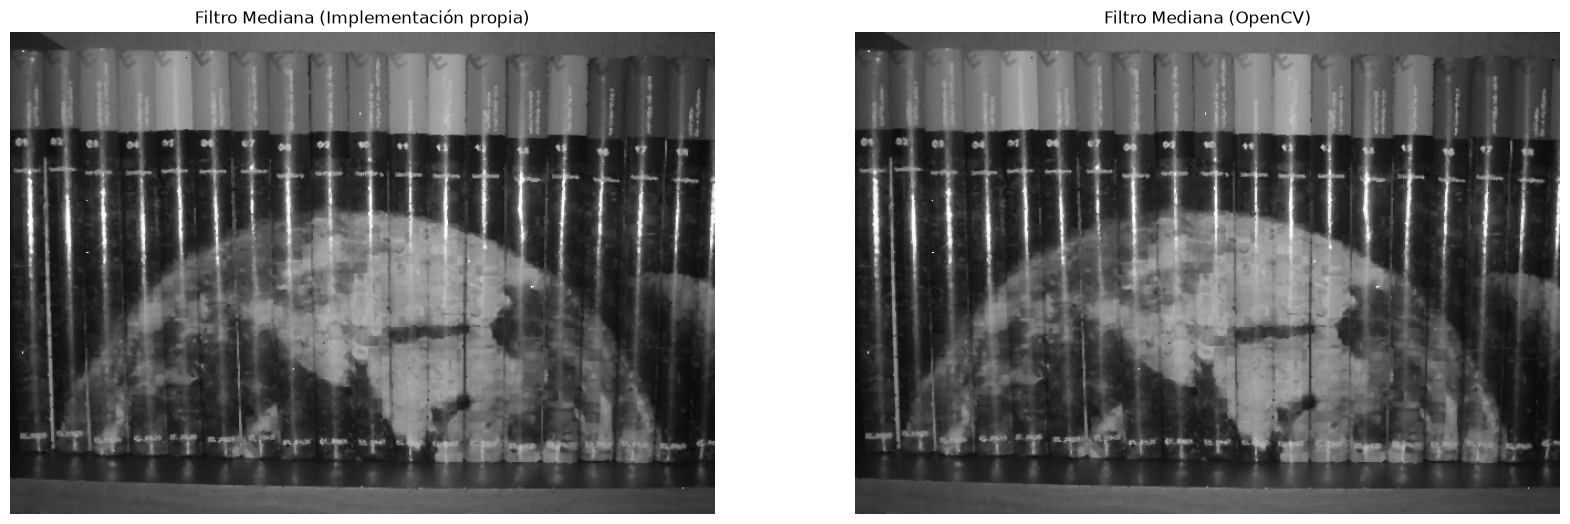

In [56]:
fig = plt.figure(figsize=(20,10))
plt.subplot(1,2,1)
plt.imshow(filt_med, cmap="gray")
plt.title("Filtro Mediana (Implementación propia)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(medBlur, cmap="gray")
plt.title("Filtro Mediana (OpenCV)")
plt.axis("off")
plt.show()

### 2.3.- Filtro adaptativo

a. Implementa las funciones que realizan un filtrado adaptativo sobre una imagen de entrada, filtro_adaptativo_v1 y filtro_adaptativo_v2, y guárdalas en el fichero Python funciones_filtro_adapatativo.py. Las entradas de ambas funciones deben ser:

- I: np.ndarray, imagen de entrada 2D.

- V: np.ndarray, matriz de vecindad (de dimensiones impares), compuesta por 0s y 1s. Solo los píxeles donde V=1 se usan para calcular la media y desviación típica local.

- VarRuido: varianza del ruido.

- opcionrelleno: string, que indica el tipo de padding: 'replicate', 'reflect' o 'zeros' (por defecto 'reflect').

- La función devuelve Io, np.ndarray tipo float64, matriz resultante tras aplicar el filtro.

**Observaciones de implementación:**

- La versión 1 de la función debe implementarse recorriendo píxel a píxel la imagen.

- La versión 2 debe implementarse de forma matricial. Para ello, se facilita la función stdfilt, que calcula la desviación típica local (sobre una vecindad dada) de cada punto de una matriz de entrada.

- Todas las operaciones en ambas funciones se deben realizar en float64.

- Para evitar desbordamientos en los valores resultantes de la expresión que implementa el filtrado, los valores del factor VarRuido/VarLocal (varianza local) deben limitarse a un rango de variación 0-1.

- Para prevenir la división por cero, en caso de desviación típica local cero se debe sustituir su valor por el menor número positivo representable: np.finfo(np.float64).eps

In [11]:
from funcion_stdfilt import stdfilt

EPS = np.finfo(np.float64).eps

def _comprobar(I, V):
    if I.ndim != 2:
        raise ValueError("I debe ser una imagen 2D")
    if V.ndim != 2 or V.shape[0] % 2 == 0 or V.shape[1] % 2 == 0:
        raise ValueError("V debe ser 2D y de dimensiones impares")
    if not np.any(V):
        raise ValueError("V debe tener al menos un 1")

def filtro_adaptativo_v1(I: np.ndarray, V: np.ndarray, VarRuido: float, opcionrelleno: str = 'replicate') -> np.ndarray:
    _comprobar(I, V)
    I = I.astype(np.float64)
    mascara = V.astype(bool)
    alto, ancho = I.shape
    nf, nc = V.shape

    relleno = {
        'replicate': cv2.BORDER_REPLICATE,
        'reflect': cv2.BORDER_REFLECT,
        'constant': cv2.BORDER_CONSTANT

    }

    pad = cv2.copyMakeBorder(I, nf // 2, nf // 2, nc // 2, nc // 2, relleno[opcionrelleno])
    Io = np.zeros((alto, ancho), dtype=np.float64)

    for i in range(alto):
        for j in range(ancho):
            ventana = pad[i:i + nf, j:j + nc]
            valores = ventana[mascara]

            media = np.mean(valores)
            desv = np.std(valores)
            if desv == 0:
                desv = EPS
            var_local = desv ** 2

            factor = np.clip(VarRuido / var_local, 0.0, 1.0)
            Io[i, j] = I[i, j] - factor * (I[i, j] - media)
    return Io


def filtro_adaptativo_v2(I: np.ndarray, V: np.ndarray, VarRuido: float, opcionrelleno: str = 'replicate') -> np.ndarray:
    _comprobar(I, V)
    I = I.astype(np.float64)
    Vb = (V > 0).astype(np.float64)
 
    
    media = cv2.filter2D(I, -1, Vb / Vb.sum(), borderType=_MODOS_CV[opcionrelleno])
 
    
    desv = stdfilt(I, Vb, opcionrelleno)
    desv[desv == 0] = EPS                                
    var_local = desv ** 2
 
    factor = np.clip(VarRuido / var_local, 0.0, 1.0)
    return I - factor * (I - media)


        

b. Utilizando padding ‘reflect’, aplica un filtrado adaptativo 9x9 sobre la imagen corrompida con ruido sal y pimienta utilizando ambas versiones de la función. La varianza del ruido de entrada de las funciones debe ser la estimación de la varianza del ruido global presente en la imagen (debe realizarse a partir de la imagen sin corromper y la imagen con ruido sal y pimienta). Comprueba numéricamente que ambas funciones obtienen el mismo resultado (diferencias del orden de 10^(-5)).

In [5]:
from funciones_filtro_adaptativo import filtro_adaptativo_v1, filtro_adaptativo_v2

V = np.ones((9,9))

ruido = SyP.astype(np.float64) - I.astype(np.float64)
VarRuido = np.var(ruido)
print("Varianza estimada del ruido:", VarRuido)

t0 = time.perf_counter()
Io1 = filtro_adaptativo_v1(SyP, V, VarRuido, 'reflect')
t1 = time.perf_counter() - t0

t0 = time.perf_counter()
Io2 = filtro_adaptativo_v2(SyP, V, VarRuido, 'reflect')
t2 = time.perf_counter() - t0

dif = np.abs(Io1 - Io2)
print("Diferencia máxima:", dif.max())
print("Diferencia media :", dif.mean())
print("¿Iguales (tol 1e-5)?", np.allclose(Io1, Io2, atol=1e-5))
print(f"Tiempo v1: {t1:.2f} s | v2: {t2:.4f} s")



Varianza estimada del ruido: 2035.466779517097
Diferencia máxima: 1.7053025658242404e-12
Diferencia media : 2.233049885998409e-14
¿Iguales (tol 1e-5)? True
Tiempo v1: 3.48 s | v2: 0.0129 s


c. Visualiza y analiza el resultado del proceso de filtrado: imagen de entrada e imagen filtrada.

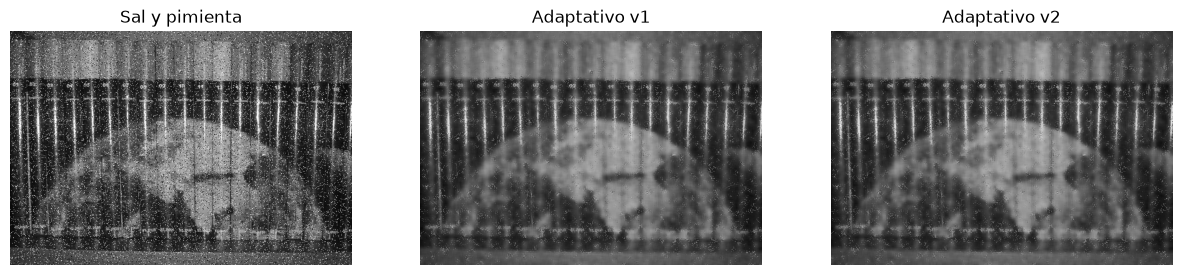

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axs, [SyP, Io1, Io2],
                     ['Sal y pimienta', 'Adaptativo v1', 'Adaptativo v2']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t); ax.axis('off')
plt.show()


Objetivos teóricos:

- Clasificación de tipos de filtrado para reducir ruido.

- Conocer los filtros representativos de cada tipología y saber sus fundamentos de operación e implementación.